# 43. Ten altcoins over the development period: the decomposition and the 24-hour reversal with frozen coin models

I ask whether the decomposition (S_in) and the 24-hour ranking reversal appear only in the Bitcoin development period. To answer, I apply the coin models frozen in notebook 17 (M0 and GBM, d4 definition, trained on 2021 and calibrated on 2022 for each coin) unchanged to one-minute spot data of the same ten coins from 2023-01-01 to 2026-05-01 and compute the same per-minute decomposition as for Bitcoin. This analysis is exploratory.

Before this notebook I had not downloaded the 2023–2026 data of nine coins (XRP, LTC, BNB, ADA, EOS, TRX, ETC, XLM, NEO) at any point in this study. In notebook 10 I read ETH data for 2020-01 to 2026-04 (shared alert budget; alert counts only, not this decomposition), and I know the Bitcoin results for the same period. I built the models only on data before the end of 2022, so 2023 onward is out of sample for them, but this is **not a preregistered holdout**.

I proceed in stages. First I fix the readings, coins, period and procedure in `43_SPEC.json` and record its SHA-256. For each coin I then reproduce notebook 17's phase-1 values exactly (2021 event count and training positives, M0 refit coefficients, 2022 thresholds and calibration alert counts of M0, M1 and GBM), which confirms the same data, features and models. Only after that do I build and save the 2023–2026 per-minute AUC parts per coin, and I pool them for the first time in the last cell.

I use the same method as for Bitcoin. Judging window: 30–240 minutes. Event definition: the coin d4 definition (4% × coin volatility / Bitcoin volatility, notebook 17 values), with window definitions H = 240 and 1440 minutes. I evaluate the scores M0, M1 (z_vol), GBM and B0 (24-hour RV) on the minutes where all four exist for the coin and define the regime as deciles of the coin's own RV over its evaluation period. My intervals come from 1,000 bootstrap draws of 7-day calendar blocks shared by all coins, which preserves the correlation of simultaneous declines across coins. I pool by the equal-weight mean over coins: pooled S_in = mean_i[π_i (AUC_in,i − ½)] / mean_i[AUC_i − ½]. As in Bitcoin Tables 3 and 6, I take positive labels from the coin's full event catalog and apply them to evaluation minutes only. The in-period window minutes of events that breach within 4 hours of the evaluation start therefore stay positive although those events are not in the event list or F (relabeling them negative would count minutes just before a real breach as negatives), and I report the number of such boundary events per coin. To keep every judging window whole, I drop the last 245 minutes of the evaluation period; I also exclude, and count, minutes within 245 minutes before a data gap (more than 5 minutes without prices), because their labels are undetermined.

I fix the readings before the results and record them in `43_SPEC.json`. A1 calls the in-progress share large if M0's pooled S_in 95% lower bound at H = 240 is at least 0.25 and not large if the upper bound is below 0.25; A3 calls the 24-hour reversal replicated if the pooled GBM − M0 standard-AUC interval lies above zero and the pooled pre-onset interval below zero, and contradicted if the standard interval lies below zero or the pre-onset interval above zero; A2 (label-only feasibility F, where F = 1 at H = 240 by Corollary 1 is an implementation check) and A4 (4-hour pooled differences) are descriptive. I exclude coins with fewer than 180 evaluation days, and I exclude coins without pre-onset positives only from pooled pre-onset quantities. A coverage caution appears in `0_coverage.csv`, but I do not use it in the readings. A replicated A3 means only that both directions appear in the equal-weight coin mean, not that it settles the dependence on a few events seen in notebook 41.

From notebook 17's folder (`HOLDOUT17_multicoin_2018_2019_v1`) I read `COIN_MODELS_FROZEN.json`, the d4 model files in `models/`, `phase1/*_train_manifest.csv` and `HOLDOUT17_RESULTS.json`. I write results only to `altcoin_dev_period_v1`; they contain no prices (times, counts, AUCs and intervals only).

In [1]:
from pathlib import Path
from collections import deque, defaultdict
import io, os, sys, json, math, time, hashlib, zipfile, warnings, urllib.request, urllib.error
import numpy as np
from numpy.lib.stride_tricks import sliding_window_view
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.stats import binomtest
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
try:
    import pyarrow  # noqa: F401
except ImportError:
    import subprocess
    subprocess.check_call([sys.executable, '-m', 'pip', '-q', 'install', 'pyarrow'])
try:
    from numba import njit
except ImportError:
    import subprocess
    subprocess.check_call([sys.executable, '-m', 'pip', '-q', 'install', 'numba'])
    from numba import njit
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    print('Not running in Colab: paths below must point to a folder with the same structure.')

DRIVE = Path('/content/drive/MyDrive')
SPOT_BASE = DRIVE / 'btc_lead_cost_results_77months_spot'      # spot results (notebooks 01–07)
FUT_BASE = DRIVE / 'btc_lead_cost_results_77months'            # futures results, read only
BINANCE = 'https://data.binance.vision/data/'
NS = 60 * 10**9
LEAD_MIN = 30; LEAD_MAX = 240; COOLDOWN = 240; COOLDOWN_MIN = 240
B = 240; MONTH_CAP = 20
EVAL_START = '2023-01-01'; EVAL_END = '2026-05-01'

_src = SPOT_BASE / 'cache' / 'DATA_SOURCE.json'
if not _src.is_file() or json.loads(_src.read_text()).get('venue') != 'spot':
    raise RuntimeError(f'Spot cache not found: {_src}. Run notebook 01 first.')
REF_PATH = SPOT_BASE / 'causal_alert_selection_v1' / 'spot_reference.json'
THR_PATH = SPOT_BASE / 'FINAL_risk_adaptive_alert_capacity_v1' / 'spot_frozen_thresholds.json'
for _p in (REF_PATH, THR_PATH):
    if not _p.is_file():
        raise FileNotFoundError(f'Results of notebooks 05 and 06 are required: {_p}')
REF = json.loads(REF_PATH.read_text())
FROZEN = json.loads(THR_PATH.read_text())
assert REF.get('venue') == 'spot' and FROZEN.get('venue') == 'spot'
TH_CAL = float(REF['TH_CAL']); TH_HIGH = float(REF['TH_HIGH']); TH_BUCKET = float(FROZEN['TH_BUCKET'])
print('SPOT cache verified. Frozen spot thresholds:', dict(TH_CAL=TH_CAL, TH_HIGH=TH_HIGH, TH_BUCKET=TH_BUCKET))


def sha256_file(p):
    return hashlib.sha256(Path(p).read_bytes()).hexdigest()
def load_btc_spot():
    px = pd.read_parquet(SPOT_BASE / 'cache' / 'BTCUSDT_1m_regularized.parquet').sort_index()
    sg = pd.read_parquet(SPOT_BASE / 'cache' / 'btc_signals_1m.parquet', columns=['z_vol', 'tsr', 'z_hs']).sort_index()
    for fr in (px, sg):
        assert isinstance(fr.index, pd.DatetimeIndex) and fr.index.tz is not None
        fr.index = fr.index.tz_convert('UTC')
    assert px.index.equals(sg.index), 'price/signal caches must share one 1-minute index'
    assert px.index.is_unique and (np.diff(px.index.asi8) == NS).all()
    return px, sg


def load_catalog(path):
    E = pd.read_csv(path)
    for c in ['peak_utc', 'onset_1pct_utc', 'breach_utc', 'confirmed_utc']:
        E[c] = pd.to_datetime(E[c], utc=True)
    E = E.sort_values('breach_utc').reset_index(drop=True)
    assert E.event_id.is_unique
    return E


def label_from_catalog(T, E):
    """1 if a 4% breach occurs 30-240 minutes after minute t (same rule as notebooks 04–07)."""
    b = E.breach_utc.astype('int64').to_numpy()
    pos = np.searchsorted(b, T + LEAD_MIN * NS, 'left')
    y = np.zeros(len(T), dtype=np.int8)
    ok = pos < len(b)
    y[ok] = (b[pos[ok]] <= T[ok] + LEAD_MAX * NS).astype(np.int8)
    return y


def ts(s):
    return pd.Timestamp(s, tz='UTC')


def in_period(T, start, end):
    return (T >= ts(start).value) & (T < ts(end).value)


def train_mask(T, valid, year=2021):
    return valid & (T >= ts(f'{year}-01-01').value) & (T < ts(f'{year + 1}-01-01').value - (LEAD_MAX + 5) * NS)


def new_logit():
    return make_pipeline(StandardScaler(), LogisticRegression(C=0.2, class_weight='balanced', max_iter=400,
                                                              solver='lbfgs', random_state=17))


def events_between(E, start, end):
    """Evaluation events: breach in [start+4h, end) so every warning window lies inside the period."""
    return E[(E.breach_utc >= ts(start) + pd.Timedelta(minutes=LEAD_MAX)) & (E.breach_utc < ts(end))].reset_index(drop=True)


# --- emit_calendar, as in notebook 05 ---
def emit_calendar(t,eligible,B=240,cap=20,cooldown_min=240):
    t=np.asarray(t,dtype=np.int64)
    eligible=np.asarray(eligible,dtype=bool)
    assert len(t)==len(eligible) and np.all(np.diff(t)>0)
    ids=np.flatnonzero(eligible)
    z=[]; mcount=0; ycount=0; pm=None; py=None; last=-(10**20)
    for k in ids:
        ti=int(t[k]); dt=pd.Timestamp(ti,tz='UTC')
        year=int(dt.year); month=year*12+int(dt.month)
        if year!=py: ycount=0; py=year
        if month!=pm: mcount=0; pm=month
        if ycount>=B or mcount>=cap or ti-last<cooldown_min*NS:continue
        z.append(ti); last=ti; ycount+=1; mcount+=1
    return np.asarray(z,dtype=np.int64)

# --- match_events, as in notebook 05 ---
def match_events(events,alerts):
    alerts=np.sort(np.asarray(alerts,dtype=np.int64))
    out=[];used=set()
    for ev in events.itertuples(index=False):
        breach=ev.breach_utc.value; onset=ev.onset_1pct_utc.value
        left=int(np.searchsorted(alerts,breach-LEAD_MAX*NS,'left'))
        right=int(np.searchsorted(alerts,breach-LEAD_MIN*NS,'right'))
        for j in range(left,right):
            if j not in used:
                used.add(j)
                out.append(dict(event_id=int(ev.event_id),breach_utc=ev.breach_utc,
                                alarm_utc=pd.Timestamp(int(alerts[j]),tz='UTC'),
                                lead_min=(breach-int(alerts[j]))/NS,
                                pre1pct=bool(alerts[j]<onset)))
                break
    return pd.DataFrame(out,columns=['event_id','breach_utc','alarm_utc','lead_min','pre1pct'])

# --- statistics, as in notebook 05 ---
def statistics(events,alerts):
    hits=match_events(events,alerts)
    n=len(alerts);N=len(events)
    return dict(alarms=n,caught=len(hits),before_1pct=int(hits.pre1pct.sum()),
                false_alarms=n-len(hits),recall=len(hits)/N,
                pre_onset_recall=int(hits.pre1pct.sum())/N,
                alert_precision=(len(hits)/n if n else 0))



def cal_fields(t):
    idx = pd.to_datetime(np.asarray(t, dtype='int64'), utc=True)
    years = idx.year.to_numpy().astype(np.int64)
    months = (idx.year.to_numpy() * 12 + idx.month.to_numpy()).astype(np.int64)
    return years, months


@njit(cache=False)
def _calendar_core(t, elig, years, months, B, caps, cooldown_ns):
    # Line-by-line port of emit_calendar with a per-minute monthly cap (caps) so a surge policy can reuse it.
    out = np.empty(len(t), np.int64); k = 0
    mcount = 0; ycount = 0; pm = -1; py = -1; last = -(2**62)
    for i in range(len(t)):
        if not elig[i]:
            continue
        ti = t[i]; yr = years[i]; mo = months[i]
        if yr != py:
            ycount = 0; py = yr
        if mo != pm:
            mcount = 0; pm = mo
        if ycount >= B or mcount >= caps[i] or ti - last < cooldown_ns:
            continue
        out[k] = ti; k += 1; last = ti; ycount += 1; mcount += 1
    return out[:k].copy()


_CAL_CACHE = [None, None]


def emit_calendar_fast(t, eligible, B=240, cap=20, cooldown_min=240, caps=None):
    t = np.asarray(t, dtype=np.int64); eligible = np.asarray(eligible, dtype=bool)
    assert len(t) == len(eligible) and (len(t) < 2 or np.all(np.diff(t) > 0))
    if _CAL_CACHE[0] is t:
        years, months = _CAL_CACHE[1]
    else:
        years, months = cal_fields(t); _CAL_CACHE[0] = t; _CAL_CACHE[1] = (years, months)
    if caps is None:
        caps = np.full(len(t), int(cap), np.int64)
    return _calendar_core(t, eligible, years, months, int(B), np.asarray(caps, np.int64), np.int64(cooldown_min * NS))


def check_fast_calendar(t, s):
    """Stop if the compiled calendar ever differs from the notebook 05 reference implementation."""
    qs = np.unique(np.quantile(s[np.isfinite(s)], [0., .5, .8, .9, .95, .99, .999]))
    for th in qs:
        e = np.isfinite(s) & (s >= th)
        for B_, cap_ in [(240, 20), (60, 5)]:
            if not np.array_equal(emit_calendar(t, e, B=B_, cap=cap_), emit_calendar_fast(t, e, B=B_, cap=cap_)):
                raise AssertionError(f'fast calendar differs from the reference at th={th}, B={B_}')
    return len(qs) * 2


def score_grid(sc):
    Q = np.unique(np.r_[0., np.linspace(.10, .995, 33), .997, .999, .9999, 1.])
    return np.unique(np.r_[np.nextafter(sc.min(), -np.inf), np.quantile(sc, Q), np.nextafter(sc.max(), np.inf)])


def calibrate_calendar(t_cal, s_cal, grid=None, B_=240, cap_=20):
    """Notebook 05 rule: the most 2022 alerts reachable (cap = B), then the fewest raw candidates (strictest)."""
    grid = score_grid(s_cal) if grid is None else grid
    rows = []
    for th in grid:
        e = s_cal >= th
        rows.append((float(th), len(emit_calendar_fast(t_cal, e, B=B_, cap=cap_)), int(e.sum())))
    df = pd.DataFrame(rows, columns=['threshold', 'cal_alerts', 'raw_candidates'])
    best = df[df.cal_alerts == df.cal_alerts.max()].sort_values('raw_candidates').iloc[0]
    return float(best.threshold), int(best.cal_alerts), df


def mcnemar_one_sided(a_only, b_only):
    """P(at least b_only successes | n discordant, p=.5): evidence that B beats A."""
    n = a_only + b_only
    return float(binomtest(b_only, n, .5, alternative='greater').pvalue) if n else 1.0


def mcnemar_two_sided(a_only, b_only):
    n = a_only + b_only
    return float(binomtest(min(a_only, b_only), n, .5).pvalue) if n else 1.0


def paired(events, base_alerts, new_alerts):
    mb = match_events(events, base_alerts); mn = match_events(events, new_alerts)
    hb, hn = set(mb.event_id), set(mn.event_id)
    pb, pn = set(mb.loc[mb.pre1pct, 'event_id']), set(mn.loc[mn.pre1pct, 'event_id'])
    return dict(base_caught=len(hb), new_caught=len(hn), base_only_caught=len(hb - hn), new_only_caught=len(hn - hb),
                p_caught_two_sided=mcnemar_two_sided(len(hb - hn), len(hn - hb)),
                base_pre1pct=len(pb), new_pre1pct=len(pn), base_only_pre1pct=len(pb - pn), new_only_pre1pct=len(pn - pb),
                p_pre1pct_two_sided=mcnemar_two_sided(len(pb - pn), len(pn - pb)),
                p_pre1pct_one_sided_new_better=mcnemar_one_sided(len(pb - pn), len(pn - pb)))
RAW_COLS = ['open_time', 'open', 'high', 'low', 'close', 'volume', 'close_time', 'quote_volume',
            'trade_count', 'taker_buy_vol', 'taker_buy_quote', 'ignore']


def month_list(first, last):
    return [p.strftime('%Y-%m') for p in pd.period_range(first, last, freq='M')]


def _fetch(url, tries=5):
    last = None
    for k in range(tries):
        try:
            req = urllib.request.Request(url, headers={'User-Agent': 'Mozilla/5.0'})
            with urllib.request.urlopen(req, timeout=120) as r:
                return r.read()
        except urllib.error.HTTPError as e:
            if e.code == 404:
                return None
            last = e
        except Exception as e:  # network hiccup: retry
            last = e
        time.sleep(2 ** k)
    raise RuntimeError(f'download failed: {url} ({last})')


def get_archives(prefix, symbol, months, dest, allow_missing=False):
    """Binance public monthly 1m klines (prefix 'spot' or 'futures/um'), SHA-256 checked against .CHECKSUM.
    Already-downloaded files whose hash matches are reused, so an interrupted run resumes."""
    dest = Path(dest); dest.mkdir(parents=True, exist_ok=True)
    rows = []
    for ym in months:
        url = f'{BINANCE}{prefix}/monthly/klines/{symbol}/1m/{symbol}-1m-{ym}.zip'
        z = dest / f'{symbol}-1m-{ym}.zip'
        chk = _fetch(url + '.CHECKSUM')
        if chk is None:
            if allow_missing:
                rows.append(dict(symbol=symbol, venue=prefix, month=ym, url=url, sha256=None, status='not_listed'))
                continue
            raise RuntimeError(f'archive not published: {url}')
        expected = chk.decode().split()[0].strip().lower()
        if z.is_file() and sha256_file(z) == expected:
            status = 'cached'
        else:
            data = _fetch(url)
            if data is None:
                raise RuntimeError(f'archive missing although checksum exists: {url}')
            if hashlib.sha256(data).hexdigest() != expected:
                raise RuntimeError(f'SHA-256 mismatch: {url}')
            part = z.parent / (z.name + '.part'); part.write_bytes(data); part.replace(z)
            status = 'downloaded'
        rows.append(dict(symbol=symbol, venue=prefix, month=ym, url=url, sha256=expected, status=status))
    man = pd.DataFrame(rows)
    print(symbol, prefix, man.status.value_counts().to_dict(), flush=True)
    return man


def parse_kline_zip(path):
    """Header or no header; ms or microsecond timestamps (spot archives switched to microseconds in 2025)."""
    with zipfile.ZipFile(path) as zf:
        members = [m for m in zf.namelist() if m.lower().endswith('.csv')]
        if len(members) != 1:
            raise ValueError(f'expected one CSV in {path}')
        with zf.open(members[0]) as fd:
            x = pd.read_csv(fd, header=None, low_memory=False)
    if str(x.iloc[0, 0]).strip().lower() in ('open_time', 'timestamp'):
        x = x.iloc[1:].reset_index(drop=True)
    if x.shape[1] < 12:
        raise ValueError(f'unexpected kline schema in {path}: {x.shape[1]} columns')
    x = x.iloc[:, :12]; x.columns = RAW_COLS
    number = pd.to_numeric(x.open_time, errors='raise')
    mag = float(number.abs().median())
    unit = 'us' if mag > 1e14 else ('ms' if mag > 1e11 else 's')
    z = x[['open', 'high', 'low', 'close', 'volume', 'taker_buy_vol']].apply(pd.to_numeric, errors='coerce')
    z.index = pd.DatetimeIndex(pd.to_datetime(number, unit=unit, utc=True), name='open_time')
    return z[~z.index.duplicated(keep='last')].sort_index().astype('float64')


def load_archives(manifest, folder):
    parts = [parse_kline_zip(Path(folder) / f"{r.symbol}-1m-{r.month}.zip") for r in manifest.itertuples() if r.status != 'not_listed']
    raw = pd.concat(parts).sort_index(kind='stable')
    return raw[~raw.index.duplicated(keep='last')]


def regularize(raw, start=None, end=None):
    """Notebook 01 gap policy: complete UTC minute grid; missing runs of <=5 minutes get forward-filled OHLC and
    zero volume; longer gaps stay NaN."""
    full = pd.date_range(raw.index.min() if start is None else start, raw.index.max() if end is None else end,
                         freq='min', tz='UTC')
    out = raw.reindex(full); out.index.name = 'open_time'
    missing = ~full.isin(raw.index)
    if missing.any():
        changes = np.r_[True, missing[1:] != missing[:-1]]
        grp = np.cumsum(changes) - 1
        runs = np.bincount(grp[missing], minlength=int(grp.max()) + 1)
        short = missing & (runs[grp] <= 5)
        for c in ['open', 'high', 'low', 'close']:
            out.loc[short, c] = out[c].ffill().loc[short]
        for c in ['volume', 'taker_buy_vol']:
            out.loc[short, c] = 0.0
    return out.astype('float64')


# --- chunked_hs, as in notebook 01 ---
def chunked_hs(close,M=32,K=8,chunk=100_000):
    p=close.to_numpy(dtype=np.float32)
    result=np.full(len(p),np.nan,dtype=np.float64)
    for start in range(M-1,len(p),chunk):
        end=min(len(p),start+chunk)
        w=sliding_window_view(p[start-M+1:end],M)
        zero_mean=w-w.mean(axis=1,keepdims=True)
        result[start:end]=np.abs(np.fft.rfft(zero_mean,axis=1))[:,-K:].mean(axis=1)
        if start==(M-1) or end==len(p): print(f'FFT computation {end:,}/{len(p):,}',flush=True)
    return pd.Series(result,index=close.index)



def compute_spot_features(px, with_hs=True):
    """Exactly the notebook 01 signal formulas (z_hs, z_vol, tsr), float32 like the cache."""
    close = px['close']
    r = np.log(close).diff()
    M = 32; rolling_min = 30 * 1440
    out = {}
    if with_hs:
        hs = chunked_hs(close, M=32, K=8)
        log_hs = np.log1p(hs)
        hs_roll = log_hs.rolling(rolling_min, min_periods=rolling_min // 2)
        out['z_hs'] = ((log_hs - hs_roll.mean().shift(1)) / hs_roll.std().shift(1).replace(0, np.nan)).astype('float32')
    rv = r.rolling(M - 1, min_periods=M - 1).std()
    lrv = np.log(rv.where(rv > 0))
    rv_base = lrv.rolling(rolling_min, min_periods=rolling_min // 2)
    out['z_vol'] = ((lrv - rv_base.mean().shift(1)) / rv_base.std().shift(1).replace(0, np.nan)).astype('float32')
    out['tsr'] = ((px.volume - px.taker_buy_vol) / px.volume.replace(0, np.nan)).clip(0, 1).astype('float32')
    return pd.DataFrame(out, index=px.index)


# --- price_only_catalog, as in notebook 07 ---
def price_only_catalog(close,volume,index,H=240,decline=.04,sustain=5,refractory=1440):
    c=np.asarray(close,dtype=np.float64)
    obs=np.isfinite(c)&(c>0)&np.isfinite(volume)&(np.asarray(volume)>0)
    prior=pd.Series(np.where(obs,c,np.nan)).rolling(H,min_periods=H).max().shift(1).to_numpy()
    raw=obs & np.isfinite(prior) & (c<=(1-decline)*prior)
    fresh=raw & ~np.r_[False,raw[:-1]]
    rows=[];last_confirm=-10**12
    for i in np.flatnonzero(fresh):
        if i+sustain>len(c) or i-last_confirm<refractory:continue
        threshold=(1-decline)*prior[i]
        if not(obs[i:i+sustain].all() and np.all(c[i:i+sustain]<=threshold)):continue
        if i-H<0 or not obs[i-H:i].all():continue
        prev=c[i-H:i];peak_i=int(i-H+np.argmax(prev))
        if peak_i<=last_confirm:continue
        onset_candidates=np.flatnonzero(c[peak_i+1:i+1]<=.99*c[peak_i])
        if not len(onset_candidates):continue
        oi=int(peak_i+1+onset_candidates[0])
        rows.append({'event_id':len(rows)+1,'peak_utc':index[peak_i],
                     'onset_1pct_utc':index[oi], 'breach_utc':index[i],
                     'confirmed_utc':index[i+sustain-1],
                     'peak_close':float(c[peak_i]),'breach_close':float(c[i]),
                     'decline_at_breach_pct':(c[i]/c[peak_i]-1)*100,
                     'peak_to_breach_minutes':i-peak_i,
                     'onset_to_breach_minutes':i-oi})
        last_confirm=i+sustain-1
    df=pd.DataFrame(rows)
    if not len(df):raise RuntimeError('No price-only crash events generated; inspect price history')
    df['year']=pd.DatetimeIndex(df.breach_utc).year
    return df

# Shared with notebook 16 (identical code): VPIN, causal feature set, GBM settings.
REGIME_WINDOW_D = 30; RV_WINDOW = 1440; VPIN_BUCKETS_PER_DAY = 50; VPIN_WINDOW = 50; VPIN_LOOKBACK_D = 30
GBM_PARAMS = dict(max_iter=300, learning_rate=0.05, max_leaf_nodes=31, min_samples_leaf=200, l2_regularization=1.0,
                  class_weight='balanced', early_stopping=False, random_state=17)
FEATS = ['z_vol', 'tsr', 'z_hs', 'ret_5', 'ret_15', 'ret_60', 'ret_240', 'rv_15', 'rv_60', 'rv_240', 'rv_ratio_15_240',
         'dd_240', 'dd_1440', 'vol_intensity_15', 'sell_ratio_15', 'sell_ratio_60', 'vpin']

@njit(cache=False)
def _vpin_core(vol, buy, bucket, n_win):
    out = np.full(len(vol), np.nan); ring = np.zeros(n_win); k = 0; run = 0.0; cv = 0.0; cb = 0.0
    for i in range(len(vol)):
        v = vol[i]; b = buy[i]
        if not (v == v) or not (b == b) or v < 0:
            v = 0.0; b = 0.0
        cv += v; cb += min(max(b, 0.0), v)
        bs = bucket[i]
        if bs == bs and bs > 0 and cv >= bs:
            imb = abs(2.0 * cb - cv) / cv
            j = k % n_win; run += imb - ring[j]; ring[j] = imb; k += 1; cv = 0.0; cb = 0.0
        if k >= n_win:
            out[i] = run / n_win
    return out


def vpin_series(px):
    vol = px.volume.to_numpy(float); buy = px.taker_buy_vol.to_numpy(float)
    daily = px.volume.groupby(px.index.floor('D')).sum()
    size = (daily.rolling(VPIN_LOOKBACK_D, min_periods=VPIN_LOOKBACK_D).mean().shift(1) / VPIN_BUCKETS_PER_DAY)
    bucket = size.reindex(px.index.floor('D')).to_numpy(float)
    return _vpin_core(vol, buy, bucket, VPIN_WINDOW)


def causal_features(px, sg):
    c = px.close.astype(float); lc = np.log(c); r = lc.diff(); vol = px.volume.astype(float); sell = vol - px.taker_buy_vol.astype(float)
    F = pd.DataFrame(index=px.index)
    F['z_vol'] = sg.z_vol.astype(float); F['tsr'] = sg.tsr.astype(float); F['z_hs'] = sg.z_hs.astype(float)
    for k in (5, 15, 60, 240):
        F[f'ret_{k}'] = lc - lc.shift(k)
    for k in (15, 60, 240):
        F[f'rv_{k}'] = r.rolling(k, min_periods=k // 2).std()
    F['rv_ratio_15_240'] = F.rv_15 / F.rv_240
    F['dd_240'] = 1 - c / c.rolling(240, min_periods=120).max()
    F['dd_1440'] = 1 - c / c.rolling(1440, min_periods=720).max()
    F['vol_intensity_15'] = vol.rolling(15, min_periods=8).sum() / (vol.rolling(1440, min_periods=720).sum() / 96)
    F['sell_ratio_15'] = sell.rolling(15, min_periods=8).sum() / vol.rolling(15, min_periods=8).sum()
    F['sell_ratio_60'] = sell.rolling(60, min_periods=30).sum() / vol.rolling(60, min_periods=30).sum()
    F['vpin'] = vpin_series(px)
    return F.replace([np.inf, -np.inf], np.nan).astype('float32')
# Shared by notebooks 18 and 19: exact block-bootstrap AUC decomposition.
def week_pairs(sp, wp, sn, wn):
    """C[k, l] = over positives in block k, the number of negatives in block l with a lower score (+0.5 per tie).
    With block multiplicities w from the bootstrap, the AUC is w'Cw / ((w'P)(w'N)); w = 1 gives the ordinary AUC."""
    C = np.zeros((N_WEEKS, N_WEEKS))
    if len(sp) == 0 or len(sn) == 0:
        return C
    o = np.lexsort((sn, wn)); sn = sn[o]; wn = wn[o]
    bounds = np.searchsorted(wn, np.arange(N_WEEKS + 1), 'left')
    for l in range(N_WEEKS):
        a, b = bounds[l], bounds[l + 1]
        if a == b:
            continue
        seg = sn[a:b]; lo = np.searchsorted(seg, sp, 'left'); hi = np.searchsorted(seg, sp, 'right')
        C[:, l] = np.bincount(wp, weights=lo + 0.5 * (hi - lo), minlength=N_WEEKS)
    return C


def _ratio(a, b):
    return a / b if b > 0 else np.nan


STAT_KEYS = ['auc_standard', 'auc_pre', 'auc_in', 'share_in', 'diff_standard_minus_pre', 'in_share_of_excess', 'auc_calm',
             'auc_standard_within_regime', 'auc_pre_within_regime', 'auc_in_within_regime']


def make_parts(sm, code, calm, wk, dec):
    neg = code == 0; pre = code == 1; inn = code == 2; cnt = lambda k: np.bincount(wk[k], minlength=N_WEEKS).astype(float)
    P = dict(C_pre=week_pairs(sm[pre], wk[pre], sm[neg], wk[neg]), C_in=week_pairs(sm[inn], wk[inn], sm[neg], wk[neg]),
             C_calm=week_pairs(sm[(code > 0) & calm], wk[(code > 0) & calm], sm[neg & calm], wk[neg & calm]),
             P_pre=cnt(pre), P_in=cnt(inn), N=cnt(neg), P_calm=cnt((code > 0) & calm), N_calm=cnt(neg & calm),
             Cs_pre=np.zeros((N_WEEKS, N_WEEKS)), Cs_in=np.zeros((N_WEEKS, N_WEEKS)), Pq_pre=[], Pq_in=[], Nq=[])
    for q in range(10):
        kq = dec == q; nq = neg & kq; pq = pre & kq; iq = inn & kq
        P['Cs_pre'] += week_pairs(sm[pq], wk[pq], sm[nq], wk[nq]); P['Cs_in'] += week_pairs(sm[iq], wk[iq], sm[nq], wk[nq])
        P['Pq_pre'].append(cnt(pq)); P['Pq_in'].append(cnt(iq)); P['Nq'].append(cnt(nq))
    for k in ('Pq_pre', 'Pq_in', 'Nq'):
        P[k] = np.array(P[k])
    return P


def stats_from(P, w):
    q = lambda C: w @ C @ w
    Wn = w @ P['N']; Wp = w @ P['P_pre']; Wi = w @ P['P_in']; sp = q(P['C_pre']); si = q(P['C_in'])
    std = _ratio(sp + si, (Wp + Wi) * Wn); pre = _ratio(sp, Wp * Wn); inn = _ratio(si, Wi * Wn); pi = _ratio(Wi, Wp + Wi)
    nq = P['Nq'] @ w; pq = P['Pq_pre'] @ w; iq = P['Pq_in'] @ w; ssp = q(P['Cs_pre']); ssi = q(P['Cs_in'])
    return dict(auc_standard=std, auc_pre=pre, auc_in=inn, share_in=pi, diff_standard_minus_pre=std - pre,
                in_share_of_excess=_ratio(pi * (inn - 0.5), std - 0.5) if np.isfinite(inn) else 0.0,
                auc_calm=_ratio(q(P['C_calm']), (w @ P['P_calm']) * (w @ P['N_calm'])),
                auc_standard_within_regime=_ratio(ssp + ssi, ((pq + iq) * nq).sum()),
                auc_pre_within_regime=_ratio(ssp, (pq * nq).sum()), auc_in_within_regime=_ratio(ssi, (iq * nq).sum()))
import gc, shutil
import joblib

OUT = SPOT_BASE / 'altcoin_dev_period_v1'; (OUT / 'coins').mkdir(parents=True, exist_ok=True)
OUT17 = SPOT_BASE / 'HOLDOUT17_multicoin_2018_2019_v1'                 # read only
ZIPS = Path('/content/altcoin43_zips') if Path('/content').exists() else OUT / 'zips'
COINS = ['ETHUSDT', 'XRPUSDT', 'LTCUSDT', 'BNBUSDT', 'ADAUSDT', 'EOSUSDT', 'TRXUSDT', 'ETCUSDT', 'XLMUSDT', 'NEOUSDT']
MONTHS = month_list('2020-11', '2026-04'); P1_MONTHS = month_list('2020-11', '2022-12')
DLAST = pd.Timestamp('2026-04-30 23:59', tz='UTC')
DNAME = 'd4'; SCORES = ['M0_VF_logit', 'M1_vol_threshold', 'M3_GBM_rich', 'B0_RV24h_baseline']; MODEL_SCORES = ['M0_VF_logit', 'M3_GBM_rich']
A_NAME, B_NAME = 'M3_GBM_rich', 'M0_VF_logit'
H_LIST = [240, 1440]; H_REF, H_24 = 240, 1440
BLOCK_DAYS = 7; N_BOOT = 1000; SEED = 20261143
MIN_EVAL_DAYS = 180; WARMUP_DAYS = 1
A1_THRESHOLD = 0.25
DELETE_ZIPS_AFTER = True
MOCK_BYPASS = ()                      # empty on Colab; only the synthetic test run lists guard names here, and every bypass is printed and recorded
NWG = int(np.ceil((ts(EVAL_END) - ts(EVAL_START)).total_seconds() / (BLOCK_DAYS * 86400)))     # common calendar blocks for every coin
N_WEEKS = NWG                                                                                   # used by the shared make_parts / week_pairs
GUARDS = []


def guard(name, ok, msg):
    ok = bool(ok); byp = (not ok) and (name in MOCK_BYPASS)
    GUARDS.append(dict(guard=name, passed=ok, bypassed_in_mock=byp, detail=str(msg)))
    if ok:
        return True
    if byp:
        print(f'Guard "{name}" bypassed: {msg} (synthetic test run only)', flush=True)
        return False
    raise RuntimeError(f'GUARD FAIL: {msg}')


for _p in [OUT17 / 'COIN_MODELS_FROZEN.json', OUT17 / 'HOLDOUT17_RESULTS.json']:
    if not _p.is_file():
        raise FileNotFoundError(f'Results of notebook 17 are required: {_p}')
FROZEN_SHA = sha256_file(OUT17 / 'COIN_MODELS_FROZEN.json')
guard('frozen_sha_nb17', FROZEN_SHA == json.loads((OUT17 / 'HOLDOUT17_RESULTS.json').read_text())['frozen_sha256'],
      'COIN_MODELS_FROZEN.json differs from the file notebook 17 evaluated')
FROZEN17 = json.loads((OUT17 / 'COIN_MODELS_FROZEN.json').read_text())

SPEC = {'title': 'Ten altcoins over the development period 2023-01-01 to 2026-05-01: per-minute decomposition and the 24-hour ranking reversal with the notebook-17 frozen coin models (exploratory)',
        'coins': COINS, 'window': [EVAL_START, EVAL_END], 'archives': [MONTHS[0], MONTHS[-1]],
        'prior_use': 'XRP, LTC, BNB, ADA, EOS, TRX, ETC, XLM, NEO 2023-2026 data not downloaded before in this study; ETH 2020-01..2026-04 read in notebook 10 (shared alert budget, alert counts only); '
                     'Bitcoin results for this period known; models fitted on 2021 and calibrated on 2022 (notebook 17), so 2023-2026 is outside their fitting data; not a registered holdout',
        'models': {'source': f'notebook-17 COIN_MODELS_FROZEN.json (sha256 {FROZEN_SHA}), definition {DNAME}, read only', 'scores': SCORES,
                   'M1': 'z_vol', 'B0': '24-hour realized volatility of one-minute log returns (1440 minutes, at least 720)'},
        'checks_before_evaluation': 'per coin: the notebook-17 phase-1 manifest exists and the 2020-11..2022-12 archive SHA-256 equal it; 2021 event count and training positives, M0 refit coefficients, '
                                    'and 2022 thresholds and calibration alert counts of M0, M1 and GBM reproduce notebook 17 phase 1; during evaluation: F = 1 at H = 240 and '
                                    'standard AUC - 1/2 = (1 - pi)(pre-onset AUC - 1/2) + pi (in-progress AUC - 1/2) for every coin, definition and score',
        'evaluation': {'per_coin_window': f'[max({EVAL_START}, first UTC day with finite z_vol and z_hs + {WARMUP_DAYS} day), min({EVAL_END}, end of the last published month)); '
                                          f'minutes within 245 minutes of the end dropped; coin excluded if fewer than {MIN_EVAL_DAYS} days',
                       'definitions': 'price-only catalog with the coin d4 decline, look-back H in {240, 1440} minutes; judging window 30-240 minutes; in progress = at or after the 1% onset',
                       'labels': 'positives from the coin full catalog on evaluation minutes (Bitcoin convention); events breaching within 240 minutes after the start are not in the event list or F '
                                 'but their in-window minutes stay positive; their number is reported',
                       'data_gaps': 'minutes with a missing-price run (more than 5 minutes) within the next 245 minutes are excluded (label not determinable); counted',
                       'coverage_caution': 'reported, not used in the readings: common-minute share of evaluation minutes below 80% or a missing month in the evaluation period',
                       'minutes': 'valid minutes with all four scores finite and an RV decile', 'regime': "deciles of the coin's own RV over its evaluation minutes",
                       'quantities': 'standard, pre-onset, in-progress and within-regime pre-onset AUC; pi; S_in; GBM - M0 differences',
                       'pooling': 'equal-weight mean over coins (pre-onset quantities over coins with pre-onset positives); pooled S_in = mean(pi (AUC_in - 1/2)) / mean(AUC - 1/2)',
                       'bootstrap': f'{N_BOOT} draws of {BLOCK_DAYS}-day calendar blocks common to all coins ({NWG} blocks), 95% percentile intervals over finite draws',
                       'F': 'share of evaluation events whose onset-to-breach gap is at most 239 minutes (some pre-onset minute in the judging window)'},
        'readings': {'A1': f'H=240: M0 pooled S_in lower bound >= {A1_THRESHOLD} -> in-progress share large; upper bound < {A1_THRESHOLD} -> not large; otherwise inconclusive',
                     'A2': 'F at H=1440 per coin and pooled (sum of events): descriptive; F at H=240 must equal 1 by Corollary 1 (implementation check; stops otherwise)',
                     'A3': 'H=1440: pooled GBM - M0 standard-AUC interval above zero AND pooled pre-onset interval below zero -> replicated; standard interval below zero OR pre-onset interval above zero -> contradicted; '
                           'otherwise inconclusive; per-coin direction counts reported',
                     'A4': 'H=240 pooled GBM - M0 differences (standard, pre-onset, in-progress, within-regime pre-onset): descriptive',
                     'finite_draws': 'A1 and A3 are inconclusive when an interval end is not finite or fewer than 95% of draws are finite'},
        'seed': SEED, 'status': 'exploratory; frozen coin models; development period; no confirmatory plan changed; notebook-17 folder read only'}
_raw = (json.dumps(SPEC, indent=2, sort_keys=True, default=str) + '\n').encode()
_sp = OUT / '43_SPEC.json'
if _sp.exists() and _sp.read_bytes() != _raw:
    if any((OUT / 'coins').glob('*_parts.npz')):
        raise RuntimeError('The SPEC cannot change once evaluation parts exist (empty the coins/ folder or use a new folder).')
    _sp.rename(OUT / f'43_SPEC.replaced_{pd.Timestamp.now(tz="UTC"):%Y%m%dT%H%M%S}.json')
_sp.write_bytes(_raw); SPEC_SHA = hashlib.sha256(_raw).hexdigest()
(OUT / '43_SPEC.sha256').write_text(SPEC_SHA + '  43_SPEC.json\n')
print('SPEC fixed before any 2023-2026 altcoin data is read. SHA-256:', SPEC_SHA, '| skipped checks:', MOCK_BYPASS if MOCK_BYPASS else 'none')

Mounted at /content/drive
SPOT cache verified. Frozen spot thresholds: {'TH_CAL': 0.6698990591069133, 'TH_HIGH': 0.6864782740093911, 'TH_BUCKET': 0.7166067355142407}
SPEC fixed before any 2023-2026 altcoin data is read. SHA-256: e1e10288ceb9a2d440b3707f48f49ad009e94d642cbe8488f2a02e0862bc588c | skipped checks: none


## Shared functions

I reuse the code of notebook 17, writing only the manifests to this folder.

In [2]:
def valid_mask(reg, F):                                         # as in notebook 17
    c = reg.close.to_numpy(float); v = reg.volume.to_numpy(float)
    z = F.z_vol.to_numpy(float); f = F.tsr.to_numpy(float); h = F.z_hs.to_numpy(float)
    return np.isfinite(c) & (c > 0) & np.isfinite(v) & (v > 0) & np.isfinite(z) & np.isfinite(f) & np.isfinite(h) & (f >= 0) & (f <= 1)


def score(mname, F, rows, model):                              # as in notebook 17
    S = np.full(len(F), np.nan)
    if mname == 'M1_vol_threshold':
        S[rows] = F.z_vol.to_numpy(float)[rows]
    elif mname == 'M2_VPIN':
        S[rows] = F.vpin.to_numpy(float)[rows]
    elif mname == 'M0_VF_logit':
        X = F[['z_vol', 'tsr']].to_numpy(float); ok = rows & np.isfinite(X).all(axis=1)
        S[ok] = model.predict_proba(X[ok])[:, 1]
    else:
        X = F[FEATS].to_numpy(np.float32); S[rows] = model.predict_proba(X[rows])[:, 1]
    return S


def load_frozen_model(sym, mname):
    c = FROZEN17[sym]['configs'][f'{mname}|{DNAME}']; p = OUT17 / c['model_file']
    guard(f'model_sha|{sym}|{mname}', p.is_file() and sha256_file(p) == c['model_sha256'], f'{sym} {mname} {DNAME}: model file missing or SHA-256 differs from the freeze')
    return joblib.load(p)


TCOLS = ['peak_utc', 'onset_1pct_utc', 'breach_utc', 'confirmed_utc']


def catalog(close, volume, index, H, decline):
    E = price_only_catalog(close, volume, index, H=H, decline=decline)
    for c_ in TCOLS:
        E[c_] = pd.to_datetime(E[c_], utc=True)
    return E.sort_values('breach_utc').reset_index(drop=True)


def codes(T, E):
    """0 negative, 1 pre-onset positive, 2 in-progress positive (notebook-18 rule)."""
    y = label_from_catalog(T, E); br = E.breach_utc.astype('int64').to_numpy(); on = E.onset_1pct_utc.astype('int64').to_numpy()
    pos = np.searchsorted(br, T + LEAD_MIN * NS, 'left'); ok = pos < len(br)
    inn = np.zeros(len(T), bool); inn[ok] = T[ok] >= on[pos[ok]]
    return np.where(y == 1, np.where(inn & (y == 1), 2, 1), 0).astype(np.int64)

## 1. Per coin: download, reproduce notebook 17 phase 1, save the 2023–2026 AUC parts

This section computes no pooled result. For each coin I save the evaluation period, event counts and F to `coins/{coin}_meta.json` and the pair counts per block to `coins/{coin}_parts.npz` (no prices).

In [3]:
t_all = time.time()
for sym in COINS:
    meta_p = OUT / 'coins' / f'{sym}_meta.json'; parts_p = OUT / 'coins' / f'{sym}_parts.npz'
    if meta_p.is_file():
        mt = json.loads(meta_p.read_text())
        if mt.get('spec_sha256') == SPEC_SHA and mt.get('frozen_sha256') == FROZEN_SHA and (mt.get('excluded') or parts_p.is_file()):
            print(sym, 'already done' + (f' (excluded: {mt["excluded"]})' if mt.get('excluded') else '')); continue
    t0 = time.time(); entry = FROZEN17[sym]; meta = dict(symbol=sym, spec_sha256=SPEC_SHA, frozen_sha256=FROZEN_SHA); g0 = len(GUARDS)
    if f'M0_VF_logit|{DNAME}' not in entry.get('configs', {}):
        meta['excluded'] = f'no frozen {DNAME} configuration in notebook 17'; meta_p.write_text(json.dumps(meta, indent=2)); continue
    man = get_archives('spot', sym, MONTHS, ZIPS / sym, allow_missing=True); man.to_csv(OUT / 'coins' / f'{sym}_manifest.csv', index=False)
    meta['manifest_sha256'] = sha256_file(OUT / 'coins' / f'{sym}_manifest.csv'); listed = man[man.status != 'not_listed']
    # ---- check 1: the 2020-11..2022-12 archives are the ones notebook 17 used
    m17p = OUT17 / 'phase1' / f'{sym}_train_manifest.csv'
    guard(f'phase1_manifest_exists|{sym}', m17p.is_file(), f'{sym}: notebook-17 phase-1 manifest not found ({m17p})')
    if m17p.is_file():
        m17 = pd.read_csv(m17p); m17 = m17[m17.status != 'not_listed'].set_index('month'); mine = man.set_index('month')
        diff = [m for m in P1_MONTHS if (m in m17.index) != (m in mine.index and mine.loc[m, 'status'] != 'not_listed') or
                (m in m17.index and str(m17.loc[m, 'sha256']) != str(mine.loc[m, 'sha256']))]
        guard(f'phase1_manifest|{sym}', not diff, f'{sym}: 2020-11..2022-12 archives differ from the notebook-17 phase-1 manifest in {diff[:6]}')
    ev_months = listed[listed.month >= EVAL_START[:7]]
    if len(ev_months) == 0:
        meta['excluded'] = 'no archives published in the evaluation period'; meta['guards'] = GUARDS[g0:]; meta_p.write_text(json.dumps(meta, indent=2)); print(sym, meta['excluded']); continue
    last = min(DLAST, (pd.Period(listed.month.max(), 'M') + 1).start_time.tz_localize('UTC') - pd.Timedelta(minutes=1))
    reg = regularize(load_archives(listed, ZIPS / sym), end=last).loc[:last]
    base = compute_spot_features(reg); F = causal_features(reg, base); del base
    T = reg.index.asi8; close = reg.close.to_numpy(float); volume = reg.volume.to_numpy(float); VALID = valid_mask(reg, F)
    # ---- check 2: notebook-17 phase 1 reproduced (2021 events and training positives, M0 refit, 2022 thresholds and calibration alerts)
    c0 = entry['configs'][f'M0_VF_logit|{DNAME}']; decline = float(c0['decline'])
    E240 = catalog(close, volume, reg.index, 240, decline); tr = train_mask(T, VALID); y = label_from_catalog(T, E240)
    n21 = int(((E240.breach_utc >= ts('2021-01-01')) & (E240.breach_utc < ts('2022-01-01'))).sum())
    guard(f'train_events_2021|{sym}', n21 == int(c0['train_events_2021']) and int(y[tr].sum()) == int(c0['train_positive_minutes']),
          f'{sym}: 2021 events {n21} / training positives {int(y[tr].sum())} differ from notebook 17 ({c0["train_events_2021"]} / {c0["train_positive_minutes"]})')
    MODELS = {mn: load_frozen_model(sym, mn) for mn in MODEL_SCORES}
    X = F[['z_vol', 'tsr']].to_numpy(float); okx = tr & np.isfinite(X).all(axis=1)
    refit = new_logit().fit(X[okx], y[okx]); fz = MODELS['M0_VF_logit']
    guard(f'm0_refit|{sym}', np.allclose(refit[-1].coef_, fz[-1].coef_, rtol=1e-6, atol=1e-9) and np.allclose(refit[-1].intercept_, fz[-1].intercept_, rtol=1e-6, atol=1e-9),
          f'{sym}: M0 refit on 2021 differs from the frozen notebook-17 model')
    del X, refit
    cal = VALID & in_period(T, '2022-01-01', '2023-01-01'); CALCHK = {}
    for mn in ['M0_VF_logit', 'M1_vol_threshold', 'M3_GBM_rich']:
        c = entry['configs'][f'{mn}|{DNAME}']; S_ = score(mn, F, cal, MODELS.get(mn)); okc = cal & np.isfinite(S_)
        th, ncal, _ = calibrate_calendar(T[okc], S_[okc]); CALCHK[mn] = dict(threshold=th, threshold_17=c['threshold_2022'], alerts=ncal, alerts_17=c['cal_alerts_2022'])
        guard(f'calibration_2022|{sym}|{mn}', np.isclose(th, c['threshold_2022'], rtol=1e-12, atol=0) and ncal == int(c['cal_alerts_2022']),
              f'{sym} {mn}: 2022 threshold {th} / alerts {ncal} differ from notebook 17 ({c["threshold_2022"]} / {c["cal_alerts_2022"]})')
    meta['phase1_reproduced'] = dict(train_events_2021=n21, calibration=CALCHK)
    # ---- evaluation window
    fv = T[VALID & np.isfinite(F.z_vol.to_numpy(float)) & np.isfinite(F.z_hs.to_numpy(float))]
    ev_start = max(ts(EVAL_START), pd.Timestamp(int(fv[0]), tz='UTC').ceil('D') + pd.Timedelta(days=WARMUP_DAYS)) if len(fv) else ts(EVAL_END)
    ev_end = min(ts(EVAL_END), last + pd.Timedelta(minutes=1)); days = (ev_end - ev_start).total_seconds() / 86400
    meta.update(eval_start=str(ev_start), eval_end=str(ev_end), eval_days=days)
    if days < MIN_EVAL_DAYS:
        meta['excluded'] = f'only {days:.0f} evaluation days'; meta['guards'] = GUARDS[g0:]; meta_p.write_text(json.dumps(meta, indent=2, default=str)); print(sym, meta['excluded'])
        del reg, F; gc.collect(); continue
    ev_last = ev_end.value - (LEAD_MAX + 5) * NS
    PER = (T >= ev_start.value) & (T < ev_last)
    _na = np.r_[0, np.cumsum(~np.isfinite(close))]; _ix = np.arange(len(T)); _hi = np.minimum(_ix + LEAD_MAX + 5, len(T) - 1)
    GAP_AHEAD = (_na[_hi + 1] - _na[_ix + 1]) > 0                     # a missing price within the next 245 minutes (runs <= 5 min were filled by regularize)
    EVM = VALID & PER & ~GAP_AHEAD
    ev_months_all = month_list(ev_start.strftime('%Y-%m'), (ev_end - pd.Timedelta(minutes=1)).strftime('%Y-%m'))
    miss = [m for m in ev_months_all if m not in set(listed.month)]
    meta['coverage'] = dict(eval_minutes=int(PER.sum()), valid_minutes=int((VALID & PER).sum()), excluded_gap_ahead=int((VALID & PER & GAP_AHEAD).sum()), missing_months=miss)
    # ---- scores on the evaluation minutes
    S = {mn: score(mn, F, EVM, MODELS[mn]) for mn in MODEL_SCORES}
    S['M1_vol_threshold'] = score('M1_vol_threshold', F, EVM, None)
    _lc = np.log(np.where(np.isfinite(close) & (close > 0), close, np.nan))
    RV = pd.Series(_lc).diff().rolling(RV_WINDOW, min_periods=RV_WINDOW // 2).std().to_numpy(); S['B0_RV24h_baseline'] = np.where(EVM, RV, np.nan)
    DD240 = F.dd_240.to_numpy(float); CALM = np.isfinite(DD240) & (DD240 < decline / 4)
    del F, MODELS; gc.collect()
    DEC = np.full(len(T), -1, np.int64); okr = EVM & np.isfinite(RV)
    DEC[okr] = np.minimum((pd.Series(RV[okr]).rank(pct=True).to_numpy() * 10).astype(int), 9)
    WEEK = np.where(EVM, (T - ts(EVAL_START).value) // (BLOCK_DAYS * 1440 * NS), -1).astype(np.int64)
    MC = EVM & (DEC >= 0)
    for sn in SCORES:
        MC &= np.isfinite(S[sn])
    arrays = {}; meta['events'] = {}; meta['F'] = {}; meta['positives'] = {}
    for H in H_LIST:
        E = E240 if H == 240 else catalog(close, volume, reg.index, H, decline)
        EVd = events_between(E, ev_start.strftime('%Y-%m-%d %H:%M'), ev_end.strftime('%Y-%m-%d %H:%M'))
        EVd = EVd[EVd.breach_utc.astype('int64') < ev_end.value].reset_index(drop=True)
        EVd[['event_id'] + TCOLS + ['onset_to_breach_minutes', 'peak_to_breach_minutes']].to_csv(OUT / 'coins' / f'{sym}_events_H{H}.csv', index=False)   # times only, no prices
        g = EVd.onset_to_breach_minutes.to_numpy()
        meta['events'][str(H)] = len(EVd); meta['F'][str(H)] = dict(feasible=int((g <= LEAD_MAX - 1).sum()), events=len(EVd), F=float((g <= LEAD_MAX - 1).mean()) if len(g) else np.nan)
        if H == 240 and len(EVd):
            guard(f'F_corollary1|{sym}', meta['F'][str(H)]['F'] == 1.0, f'{sym}: F at H=240 is {meta["F"][str(H)]["F"]} although Corollary 1 requires 1')
        code = codes(T, E)                                             # full-catalog labels (Bitcoin convention), see the note at the top
        br_ = E.breach_utc.astype('int64').to_numpy(); posm = MC & (code > 0)
        ev_rows = np.unique(np.searchsorted(br_, T[posm] + LEAD_MIN * NS, 'left'))
        boundary = sorted(set(E.event_id.to_numpy()[ev_rows].tolist()) - set(EVd.event_id.tolist()))
        meta['positives'][str(H)] = dict(pre=int((code[MC] == 1).sum()), in_progress=int((code[MC] == 2).sum()), negatives=int((code[MC] == 0).sum()),
                                         events_with_positives=int(len(ev_rows)), boundary_events=len(boundary),
                                         boundary_positive_minutes=int(np.isin(np.searchsorted(br_, T[posm] + LEAD_MIN * NS, 'left'), np.flatnonzero(np.isin(E.event_id.to_numpy(), boundary))).sum()))
        for sn in SCORES:
            P = make_parts(S[sn][MC], code[MC], CALM[MC], WEEK[MC], DEC[MC])
            pt = stats_from(P, np.ones(NWG))
            if np.isfinite(pt['auc_pre']) and np.isfinite(pt['auc_in']):
                lhs = pt['auc_standard'] - 0.5; rhs = (1 - pt['share_in']) * (pt['auc_pre'] - 0.5) + pt['share_in'] * (pt['auc_in'] - 0.5)
                guard(f'decomposition_identity|{sym}|{H}|{sn}', abs(lhs - rhs) <= 1e-12, f'{sym} H={H} {sn}: AUC decomposition identity off by {abs(lhs - rhs):.2e}')
            for k, v in P.items():
                arrays[f'{H}|{sn}|{k}'] = np.asarray(v, float)
    meta['common_minutes'] = int(MC.sum()); meta['blocks_with_minutes'] = int(len(np.unique(WEEK[MC])))
    meta['coverage'].update(common_minutes=int(MC.sum()), common_share=float(MC.sum() / max(1, PER.sum())),
                            caution=bool(MC.sum() / max(1, PER.sum()) < 0.8 or len(miss) > 0))
    meta['guards'] = GUARDS[g0:]; np.savez_compressed(parts_p, **arrays); meta_p.write_text(json.dumps(meta, indent=2, default=str))
    print(f'{sym}: evaluation {ev_start.date()} -> {ev_end.date()} ({days:.0f} days), events {meta["events"]}, F {{{", ".join(f"{h}: {v["F"]:.3f}" for h, v in meta["F"].items())}}}, '
          f'common minutes {meta["common_minutes"]:,} ({time.time() - t0:.0f}s)', flush=True)
    del reg, T, close, volume, VALID, S, RV, DEC, WEEK, MC, E240, arrays, PER, GAP_AHEAD, _na, _ix, _hi; gc.collect()
    if DELETE_ZIPS_AFTER and ZIPS != OUT / 'zips':
        shutil.rmtree(ZIPS / sym, ignore_errors=True)
print(f'Per-coin step done in {time.time() - t_all:.0f}s. Pooled results have not been computed yet.')

ETHUSDT spot {'downloaded': 66}
FFT computation 100,031/2,890,080
FFT computation 2,890,080/2,890,080
ETHUSDT: evaluation 2023-01-01 -> 2026-05-01 (1216 days), events {'240': 94, '1440': 242}, F {240: 1.000, 1440: 0.107}, common minutes 1,750,439 (236s)
XRPUSDT spot {'downloaded': 66}
FFT computation 100,031/2,890,080
FFT computation 2,890,080/2,890,080
XRPUSDT: evaluation 2023-01-01 -> 2026-05-01 (1216 days), events {'240': 87, '1440': 239}, F {240: 1.000, 1440: 0.121}, common minutes 1,750,439 (227s)
LTCUSDT spot {'downloaded': 66}
FFT computation 100,031/2,890,080
FFT computation 2,890,080/2,890,080
LTCUSDT: evaluation 2023-01-01 -> 2026-05-01 (1216 days), events {'240': 91, '1440': 228}, F {240: 1.000, 1440: 0.079}, common minutes 1,750,438 (221s)
BNBUSDT spot {'downloaded': 66}
FFT computation 100,031/2,890,080
FFT computation 2,890,080/2,890,080
BNBUSDT: evaluation 2023-01-01 -> 2026-05-01 (1216 days), events {'240': 51, '1440': 157}, F {240: 1.000, 1440: 0.083}, common minutes 1

## 2. Pooling: 1,000 bootstrap draws of 7-day blocks common to all coins

I see the results for the first time in this cell.

In [4]:
t_ = time.time()
INC = []; EXC = {}
for sym in COINS:
    mt = json.loads((OUT / 'coins' / f'{sym}_meta.json').read_text())
    guard(f'meta_spec|{sym}', mt.get('spec_sha256') == SPEC_SHA and mt.get('frozen_sha256') == FROZEN_SHA, f'{sym}: per-coin files were made under another SPEC or freeze')
    if mt.get('excluded'):
        EXC[sym] = mt['excluded']
    else:
        INC.append((sym, mt))
if not INC:
    raise RuntimeError('no coin has an evaluation window')
PARTS = {}
for sym, mt in INC:
    z = np.load(OUT / 'coins' / f'{sym}_parts.npz')
    for H in H_LIST:
        for sn in SCORES:
            PARTS[(sym, H, sn)] = {k: z[f'{H}|{sn}|{k}'] for k in ['C_pre', 'C_in', 'C_calm', 'P_pre', 'P_in', 'N', 'P_calm', 'N_calm', 'Cs_pre', 'Cs_in', 'Pq_pre', 'Pq_in', 'Nq']}
SYMS = [s for s, _ in INC]; ONESW = np.ones(NWG)
COV = pd.DataFrame([dict(coin=s, eval_start=mt['eval_start'], eval_end=mt['eval_end'], **{k: (v if not isinstance(v, list) else ';'.join(v)) for k, v in mt['coverage'].items()},
                         **{f'boundary_events_H{H}': mt['positives'][str(H)]['boundary_events'] for H in H_LIST},
                         **{f'boundary_positive_minutes_H{H}': mt['positives'][str(H)]['boundary_positive_minutes'] for H in H_LIST}) for s, mt in INC])
COV.to_csv(OUT / '0_coverage.csv', index=False); display(COV)
rng = np.random.default_rng(SEED)
WB = [np.bincount(rng.integers(0, NWG, NWG), minlength=NWG).astype(float) for _ in range(N_BOOT)]
KQ = ['auc_standard', 'auc_pre', 'auc_in', 'auc_pre_within_regime', 'share_in', 'in_share_of_excess']


def coin_stats(w):
    return {(sym, H, sn): stats_from(PARTS[(sym, H, sn)], w) for sym in SYMS for H in H_LIST for sn in SCORES}


def pooled(cs):
    out = {}
    for H in H_LIST:
        for sn in SCORES:
            for k in KQ[:5]:
                v = np.array([cs[(s, H, sn)][k] for s in SYMS], float); out[(H, sn, k)] = np.nanmean(v) if np.isfinite(v).any() else np.nan
            pi = np.array([cs[(s, H, sn)]['share_in'] for s in SYMS]); ai = np.array([cs[(s, H, sn)]['auc_in'] for s in SYMS]); a = np.array([cs[(s, H, sn)]['auc_standard'] for s in SYMS])
            ok = np.isfinite(pi) & np.isfinite(ai) & np.isfinite(a)
            out[(H, sn, 'S_in_pooled')] = np.mean(pi[ok] * (ai[ok] - 0.5)) / np.mean(a[ok] - 0.5) if ok.any() and np.mean(a[ok] - 0.5) > 0 else np.nan
        for k in KQ[:4]:
            d = np.array([cs[(s, H, A_NAME)][k] - cs[(s, H, B_NAME)][k] for s in SYMS], float)
            out[(H, 'GBM-M0', k)] = np.nanmean(d) if np.isfinite(d).any() else np.nan
    return out


PT_C = coin_stats(ONESW); PT_P = pooled(PT_C)
BOOT_C = []; BOOT_P = []
for i, w in enumerate(WB):
    cs = coin_stats(w); BOOT_C.append(cs); BOOT_P.append(pooled(cs))
print(f'{len(SYMS)} coins pooled ({", ".join(SYMS)}); excluded: {EXC if EXC else "none"} ({time.time() - t_:.0f}s)')


def iv(vals):
    v = np.asarray(vals, float); f = np.isfinite(v)
    return (float(np.percentile(v[f], 2.5)), float(np.percentile(v[f], 97.5)), float(f.mean())) if f.any() else (np.nan, np.nan, 0.0)


POOL_ROWS = []
for key, p_ in PT_P.items():
    lo, hi, fin = iv([b[key] for b in BOOT_P]); H, sn, k = key
    POOL_ROWS.append(dict(H=H, score=sn, quantity=k, point=p_, lo=lo, hi=hi, share_draws_finite=fin))
PO = pd.DataFrame(POOL_ROWS); PO.to_csv(OUT / '2_pooled.csv', index=False)
COIN_ROWS = []
for sym, mt in INC:
    for H in H_LIST:
        for sn in SCORES + ['GBM-M0']:
            for k in (KQ if sn != 'GBM-M0' else KQ[:4]):
                if sn == 'GBM-M0':
                    p_ = PT_C[(sym, H, A_NAME)][k] - PT_C[(sym, H, B_NAME)][k]; draws = [b[(sym, H, A_NAME)][k] - b[(sym, H, B_NAME)][k] for b in BOOT_C]
                else:
                    p_ = PT_C[(sym, H, sn)][k]; draws = [b[(sym, H, sn)][k] for b in BOOT_C]
                lo, hi, fin = iv(draws)
                COIN_ROWS.append(dict(coin=sym, H=H, score=sn, quantity=k, point=p_, lo=lo, hi=hi, share_draws_finite=fin, events=mt['events'][str(H)],
                                      F=mt['F'][str(H)]['F'], pre_onset_positives=mt['positives'][str(H)]['pre'], eval_start=mt['eval_start'], eval_end=mt['eval_end']))
PC = pd.DataFrame(COIN_ROWS); PC.to_csv(OUT / '1_per_coin.csv', index=False)

# ---- readings fixed in the SPEC
g_ = lambda H, sn, k: PO[(PO.H == H) & (PO.score == sn) & (PO.quantity == k)].iloc[0]
a1 = g_(H_REF, B_NAME, 'S_in_pooled')
A1 = ('inconclusive (finite draws)' if not (np.isfinite(a1.lo) and np.isfinite(a1.hi) and a1.share_draws_finite >= 0.95) else
      'in-progress share large (as in Bitcoin)' if a1.lo >= A1_THRESHOLD else 'in-progress share not large' if a1.hi < A1_THRESHOLD else 'inconclusive')
FROWS = []
for H in H_LIST:
    fe = sum(mt['F'][str(H)]['feasible'] for _, mt in INC); ne = sum(mt['F'][str(H)]['events'] for _, mt in INC)
    FROWS.append(dict(H=H, feasible=fe, events=ne, F=fe / ne if ne else np.nan, per_coin={s: mt['F'][str(H)]['F'] for s, mt in INC}))
d3s, d3p = g_(H_24, 'GBM-M0', 'auc_standard'), g_(H_24, 'GBM-M0', 'auc_pre')
A3 = ('inconclusive (finite draws)' if not all(np.isfinite(r.lo) and np.isfinite(r.hi) and r.share_draws_finite >= 0.95 for r in (d3s, d3p)) else
      'replicated' if (d3s.lo > 0 and d3p.hi < 0) else 'contradicted' if (d3s.hi < 0 or d3p.lo > 0) else 'inconclusive')
cs24 = {s: (PT_C[(s, H_24, A_NAME)]['auc_standard'] - PT_C[(s, H_24, B_NAME)]['auc_standard'], PT_C[(s, H_24, A_NAME)]['auc_pre'] - PT_C[(s, H_24, B_NAME)]['auc_pre']) for s in SYMS}
A3_dirs = dict(coins=len(SYMS), standard_positive_and_pre_negative=int(sum((a > 0) and (b < 0) for a, b in cs24.values())),
               standard_positive=int(sum(a > 0 for a, _ in cs24.values())), pre_negative=int(sum(b < 0 for _, b in cs24.values())),
               coins_without_pre_onset_positives=int(sum(not np.isfinite(b) for _, b in cs24.values())))
A4 = {k: dict(point=float(g_(H_REF, 'GBM-M0', k).point), lo=float(g_(H_REF, 'GBM-M0', k).lo), hi=float(g_(H_REF, 'GBM-M0', k).hi)) for k in KQ[:4]}
READ = dict(A1=A1, A1_detail=dict(point=float(a1.point), lo=float(a1.lo), hi=float(a1.hi), threshold=A1_THRESHOLD), A2=FROWS,
            A3=A3, A3_detail=dict(d_standard=[float(d3s.point), float(d3s.lo), float(d3s.hi)], d_pre=[float(d3p.point), float(d3p.lo), float(d3p.hi)], directions=A3_dirs), A4=A4)
print('A1 (M0 pooled S_in, 4 h):', A1, f'{a1.point:.3f} [{a1.lo:.3f}, {a1.hi:.3f}]')
print('A2 (F):', {r['H']: f'{r["feasible"]}/{r["events"]} = {r["F"]:.3f}' for r in FROWS})
print('A3 (24-hour reversal):', A3, f'| standard {d3s.point:+.4f} [{d3s.lo:+.4f}, {d3s.hi:+.4f}], pre-onset {d3p.point:+.4f} [{d3p.lo:+.4f}, {d3p.hi:+.4f}] | directions {A3_dirs}')
print('A4 (4 h, GBM - M0):', {k: f'{v["point"]:+.4f} [{v["lo"]:+.4f}, {v["hi"]:+.4f}]' for k, v in A4.items()})
display(PO[PO.quantity.isin(['auc_standard', 'auc_pre', 'auc_in', 'auc_pre_within_regime', 'S_in_pooled', 'share_in'])].round(4))

,coin,eval_start,eval_end,eval_minutes,valid_minutes,excluded_gap_ahead,missing_months,common_minutes,common_share,caution,boundary_events_H240,boundary_events_H1440,boundary_positive_minutes_H240,boundary_positive_minutes_H1440
0,ETHUSDT,2023-01-01 00:00:00+00:00,2026-05-01 00:00:00+00:00,1750795,1750612,173,,1750439,0.999797,False,0,0,0,0
1,XRPUSDT,2023-01-01 00:00:00+00:00,2026-05-01 00:00:00+00:00,1750795,1750612,173,,1750439,0.999797,False,0,0,0,0
2,LTCUSDT,2023-01-01 00:00:00+00:00,2026-05-01 00:00:00+00:00,1750795,1750611,173,,1750438,0.999796,False,0,0,0,0
3,BNBUSDT,2023-01-01 00:00:00+00:00,2026-05-01 00:00:00+00:00,1750795,1750612,173,,1750439,0.999797,False,0,0,0,0
4,ADAUSDT,2023-01-01 00:00:00+00:00,2026-05-01 00:00:00+00:00,1750795,1749647,173,,1749474,0.999245,False,0,0,0,0
5,EOSUSDT,2023-01-01 00:00:00+00:00,2025-06-01 00:00:00+00:00,1269835,1177576,416,,1177160,0.927018,False,0,0,0,0
6,TRXUSDT,2023-01-01 00:00:00+00:00,2026-05-01 00:00:00+00:00,1750795,1750612,173,,1750439,0.999797,False,0,0,0,0
7,ETCUSDT,2023-01-01 00:00:00+00:00,2026-05-01 00:00:00+00:00,1750795,1649810,173,,1649637,0.942222,False,0,0,0,0
8,XLMUSDT,2023-01-01 00:00:00+00:00,2026-05-01 00:00:00+00:00,1750795,1712147,173,,1711974,0.977827,False,0,0,0,0
9,NEOUSDT,2023-01-01 00:00:00+00:00,2026-05-01 00:00:00+00:00,1750795,1527152,173,,1526979,0.872163,False,0,0,0,0


10 coins pooled (ETHUSDT, XRPUSDT, LTCUSDT, BNBUSDT, ADAUSDT, EOSUSDT, TRXUSDT, ETCUSDT, XLMUSDT, NEOUSDT); excluded: none (20s)
A1 (M0 pooled S_in, 4 h): in-progress share large (as in Bitcoin) 0.692 [0.634, 0.752]
A2 (F): {240: '778/778 = 1.000', 1440: '178/1623 = 0.110'}
A3 (24-hour reversal): inconclusive | standard +0.0377 [+0.0156, +0.0618], pre-onset -0.0368 [-0.0852, +0.0196] | directions {'coins': 10, 'standard_positive_and_pre_negative': 2, 'standard_positive': 7, 'pre_negative': 5, 'coins_without_pre_onset_positives': 0}
A4 (4 h, GBM - M0): {'auc_standard': '-0.0363 [-0.0671, -0.0048]', 'auc_pre': '-0.0190 [-0.0554, +0.0202]', 'auc_in': '-0.0498 [-0.0815, -0.0192]', 'auc_pre_within_regime': '-0.0240 [-0.0635, +0.0167]'}


,H,score,quantity,point,lo,hi,share_draws_finite
0,240,M0_VF_logit,auc_standard,0.7692,0.7440,0.7936,1.0
1,240,M0_VF_logit,auc_pre,0.6864,0.6485,0.7226,1.0
2,240,M0_VF_logit,auc_in,0.8430,0.8180,0.8676,1.0
3,240,M0_VF_logit,auc_pre_within_regime,0.5967,0.5615,0.6310,1.0
4,240,M0_VF_logit,share_in,0.5430,0.5062,0.5780,1.0
5,240,M0_VF_logit,S_in_pooled,0.6923,0.6337,0.7521,1.0
6,240,M1_vol_threshold,auc_standard,0.7690,0.7436,0.7933,1.0
7,240,M1_vol_threshold,auc_pre,0.6866,0.6485,0.7228,1.0
8,240,M1_vol_threshold,auc_in,0.8425,0.8172,0.8671,1.0
9,240,M1_vol_threshold,auc_pre_within_regime,0.5966,0.5611,0.6310,1.0


## 3. Figure (per-coin and pooled 24-hour GBM − M0 differences; no prices) and summary

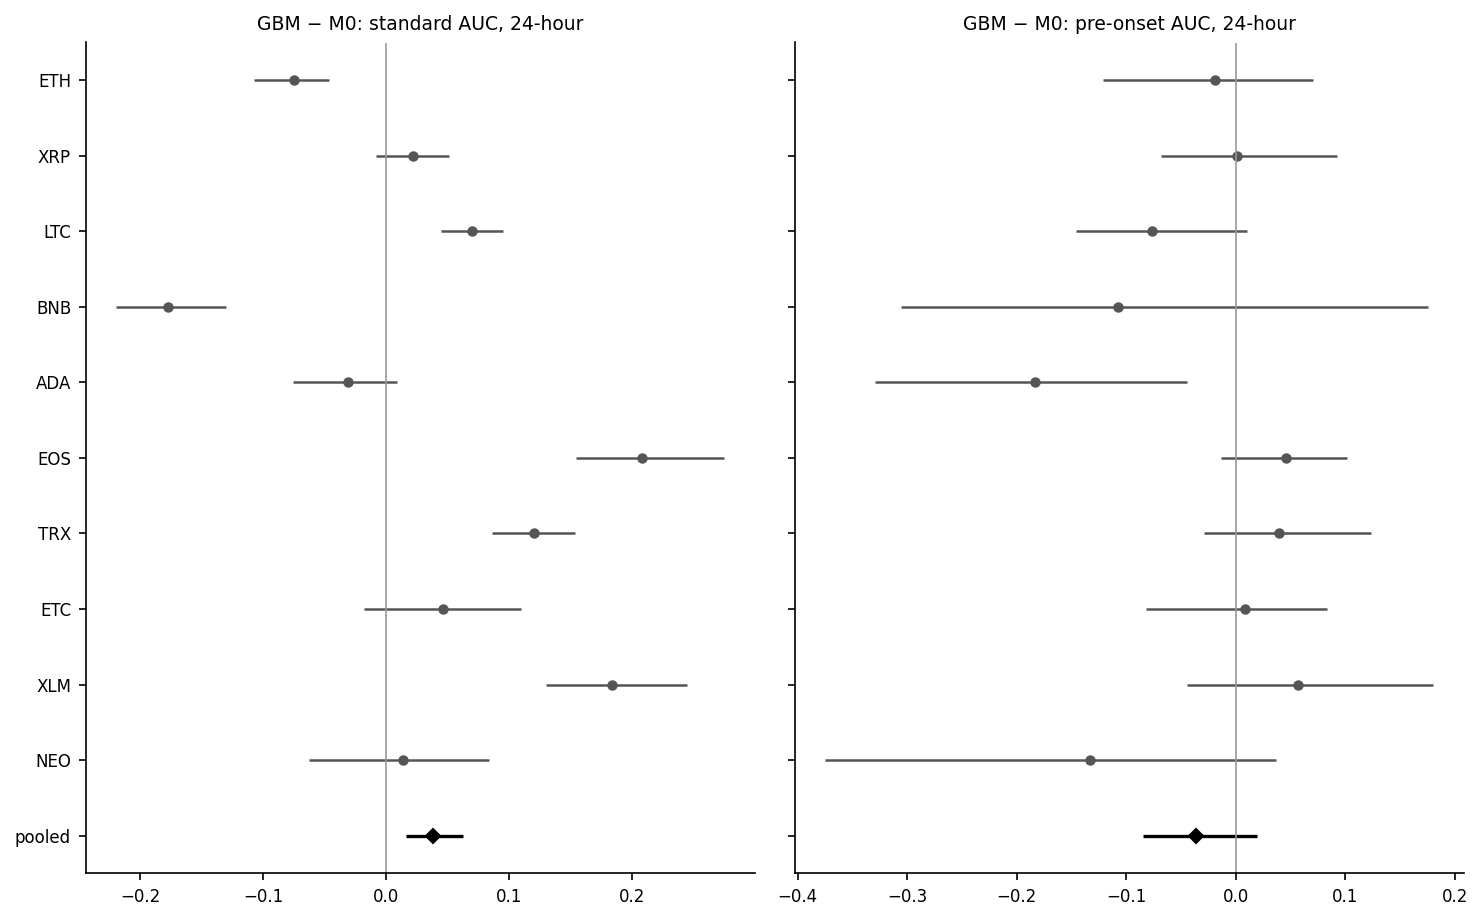

guards: 191 passed, 0 failed, 0 skipped
Done. Outputs in /content/drive/MyDrive/btc_lead_cost_results_77months_spot/altcoin_dev_period_v1


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10, 0.42 * (len(SYMS) + 2) + 1.2), dpi=150, sharey=True)
labels = SYMS + ['pooled']
for ax, k, title in zip(axes, ['auc_standard', 'auc_pre'], ['GBM − M0: standard AUC, 24-hour', 'GBM − M0: pre-onset AUC, 24-hour']):
    for i, s in enumerate(SYMS):
        r = PC[(PC.coin == s) & (PC.H == H_24) & (PC.score == 'GBM-M0') & (PC.quantity == k)].iloc[0]
        if np.isfinite(r.lo) and np.isfinite(r.hi):
            ax.hlines(i, r.lo, r.hi, color='#555555', lw=1.2)                 # interval drawn on its own: a percentile interval need not contain the point
        if np.isfinite(r.point):
            ax.plot(r.point, i, 'o', color='#555555', ms=4)
    r = g_(H_24, 'GBM-M0', k)
    if np.isfinite(r.lo) and np.isfinite(r.hi):
        ax.hlines(len(SYMS), r.lo, r.hi, color='black', lw=1.6)
    if np.isfinite(r.point):
        ax.plot(r.point, len(SYMS), 'D', color='black', ms=5)
    ax.axvline(0, color='#999999', lw=0.8); ax.set_title(title, fontsize=9); ax.tick_params(labelsize=8); ax.spines[['top', 'right']].set_visible(False)
axes[0].set_yticks(range(len(labels))); axes[0].set_yticklabels([l.replace('USDT', '') for l in labels]); axes[0].invert_yaxis()
fig.tight_layout(); fig.savefig(OUT / 'fig_altcoin_dev_24h.png'); fig.savefig(OUT / 'fig_altcoin_dev_24h.pdf'); plt.show()


def _j(o):
    if isinstance(o, (np.floating, np.integer)):
        return float(o)
    if isinstance(o, np.bool_):
        return bool(o)
    return str(o)


summary = dict(spec_sha256=SPEC_SHA, frozen_sha256=FROZEN_SHA, run_time=str(pd.Timestamp.now(tz='UTC').floor('s')), status=SPEC['status'],
               mock_bypass_used=bool(any(g['bypassed_in_mock'] for g in GUARDS)), guards=GUARDS, coins_included=SYMS, coins_excluded=EXC,
               per_coin_guards={s: json.loads((OUT / 'coins' / f'{s}_meta.json').read_text()).get('guards') for s in COINS},
               per_coin_windows={s: dict(start=mt['eval_start'], end=mt['eval_end'], days=mt['eval_days'], events=mt['events'], F=mt['F'], common_minutes=mt['common_minutes'],
                                         coverage=mt['coverage'], positives=mt['positives']) for s, mt in INC},
               readings=READ, pooled=PO.to_dict('records'), outputs=sorted(p.name for p in OUT.iterdir() if p.is_file()))
(OUT / '43_SUMMARY.json').write_text(json.dumps(summary, indent=2, default=_j))
print(f'guards: {sum(g["passed"] is True for g in GUARDS)} passed, {sum(g["passed"] is False for g in GUARDS)} failed, {sum(g["passed"] is None for g in GUARDS)} skipped'
      + (f' (bypassed in the mock: {sorted({g["guard"] for g in GUARDS if g["bypassed_in_mock"]})})' if summary['mock_bypass_used'] else ''))
print('Done. Outputs in', OUT)

## Interpretation
- A1–A4 are the pre-specified readings (cell output and `readings` in `43_SUMMARY.json`); `2_pooled.csv` holds the pooled values and `1_per_coin.csv` the per-coin values and intervals.
- For comparison, Bitcoin's development-period M0 S_in under the 4-hour definition was 0.615, and its 24-hour GBM − M0 differences were +0.057 (standard) and −0.090 (pre-onset) (Tables 3 and 6 of the main text). For the altcoins I use the d4 definition scaled to each coin's own volatility, so event sizes differ across coins (as in notebook 17).